Quick visualisation in lieu of dashboard

In [1]:
import sys
sys.path.insert(0, '..')
from src.analysis.stage8_temporal import *

In [51]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
from statsmodels.stats.multitest import multipletests

DATA = Path(r'C:\Users\User1\NLP_Reddit_Sentiment_Analysis\data\processed\new')

daily = pd.read_parquet(DATA / "daily_sentiment_2026.parquet")
changes = pd.read_parquet(DATA / "event_changes_2026.parquet")

display(daily.head())
display(changes.round(3))

print("Daily rows:", len(daily))
print("Dates:", daily["date"].min(), daily["date"].max())



,date,doc_count,pct_neg,pct_neu,pct_pos,mean_sent_neg,mean_sent_neu,mean_sent_pos,mean_net_buyin,mean_net_stance,mean_prob_buyin_committed,mean_prob_buyin_uncommitted,mean_prob_stance_supportive,mean_prob_stance_critical,low_volume,subreddit
0,2026-01-01,109,0.155963,0.587156,0.256881,0.163848,0.597354,0.238797,0.033702,0.018355,0.090137,0.056435,0.057495,0.039141,False,All
1,2026-01-02,133,0.135338,0.744361,0.120301,0.170833,0.670142,0.159025,0.023487,-0.000940,0.042962,0.019475,0.020330,0.021270,False,All
2,2026-01-03,191,0.172775,0.602094,0.225131,0.205303,0.565325,0.229371,0.000697,-0.015704,0.048015,0.047318,0.020901,0.036605,False,All
3,2026-01-04,193,0.202073,0.554404,0.243523,0.211873,0.531967,0.256160,0.016894,0.017662,0.093605,0.076711,0.042935,0.025273,False,All
4,2026-01-05,206,0.121359,0.684466,0.194175,0.158837,0.632356,0.208808,-0.014183,-0.003580,0.045504,0.059687,0.032434,0.036014,False,All


,subreddit,n_before,n_after,change_pct_neg,change_pct_neu,change_pct_pos,change_mean_sent_neg,change_mean_sent_neu,change_mean_sent_pos,change_mean_net_buyin,change_mean_net_stance,change_mean_prob_buyin_committed,change_mean_prob_buyin_uncommitted,change_mean_prob_stance_supportive,change_mean_prob_stance_critical
0,All,51500.0,3108.0,0.058,-0.039,-0.019,0.047,-0.029,-0.018,0.006,-0.012,0.023,0.017,0.015,0.028
1,NationalServiceSG,44470.0,2553.0,0.065,-0.045,-0.020,0.053,-0.034,-0.018,-0.003,-0.023,0.015,0.018,0.005,0.028
2,askSingapore,3166.0,213.0,-0.034,-0.026,0.061,-0.040,-0.009,0.049,0.006,0.003,0.020,0.013,-0.015,-0.018
3,singapore,3864.0,342.0,-0.006,0.046,-0.040,-0.003,0.033,-0.030,0.073,0.094,0.068,-0.004,0.094,0.001


Daily rows: 1207
Dates: 2026-01-01 00:00:00 2026-10-29 00:00:00


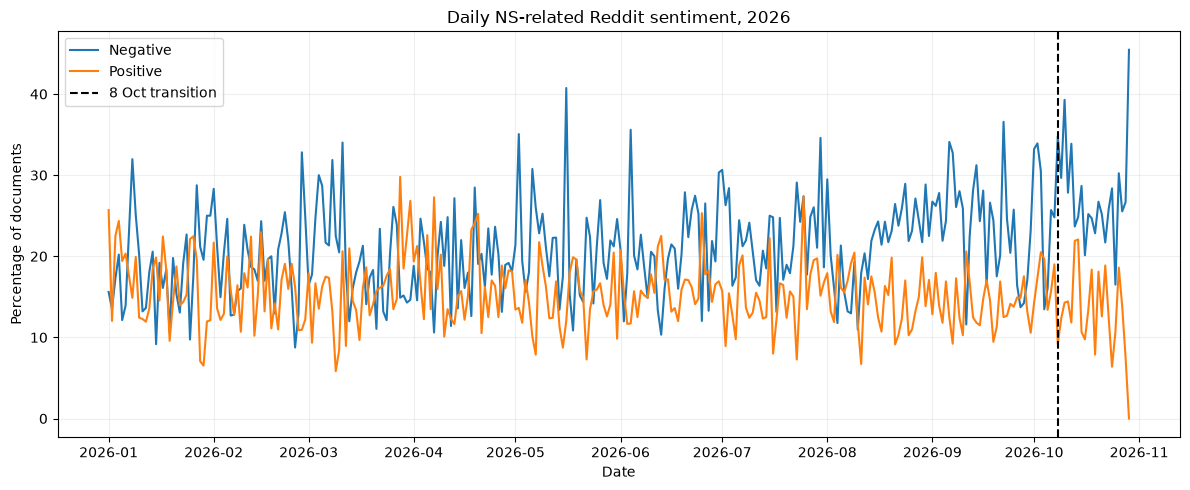

In [ ]:
overall = daily[daily["subreddit"] == "All"].sort_values("date")

fig, ax = plt.subplots(figsize=(12, 5))

ax.plot(overall["date"],overall["pct_neg"] * 100,label="Negative",)
ax.plot(overall["date"],overall["pct_pos"] * 100,label="Positive",)
ax.axvline(pd.Timestamp("2026-10-08"),color="black",linestyle="--",label="8 Oct transition",)

ax.set(title="Daily NS-related Reddit sentiment, 2026",xlabel="Date",ylabel="Percentage of documents")

ax.legend()
ax.grid(alpha=0.2)
plt.tight_layout()
plt.show()

Overall, after event on 8 October:
* Negative sentiments increased by 5.8pp
* Neutral sentiments declined by 3.9pp
* Positive sentiments declined by 1.9pp
* Average negative probability increased by 0.047

However, this is driven largely by r/NationalServiceSG, where negative sentiments increased by 6.5pp. In r/Singapore and r/askSingapore, sentiments moved in the other direction (negative sentiment decreased/remained the same). These 2 subreddits have fewer post-event documents (200-300) than r/NationalServiceSG (2553), so estimates could be less precise. 

### Follow up 1: Sensitivity analysis - do results persist under equal window sizes?
* compare similar time periods before and after the event.

In [53]:
def load():
    doc = pd.read_parquet(DATA / "doc_sentiment.parquet")

    assert doc["doc_id"].is_unique
    print(f"Loaded {len(doc):,} documents")

    required = ["doc_id", "created_utc", "subreddit","doc_type", "topic_macro","sent_neg", "sent_neu", "sent_pos","prob_buyin_committed", "prob_buyin_uncommitted","prob_stance_supportive", "prob_stance_critical",]
    missing = set(required) - set(doc.columns)
    assert not missing, f"Missing columns: {missing}"

    # Consistent Singapore calendar dates
    doc["created_utc"] = pd.to_datetime(doc["created_utc"], utc=True)
    doc["date"] = (doc["created_utc"].dt.tz_convert("Asia/Singapore").dt.tz_localize(None).dt.normalize())

    doc = doc.loc[doc["date"].dt.year.eq(2026)].copy()

    # Exclude event day from before/after comparisons
    doc["period"] = np.select(
        [
            doc["date"] < EVENT_DATE,
            doc["date"] > EVENT_DATE,
        ],
        ["before", "after"],
        default="event_day",
    )

    # One dominant sentiment per document
    doc["sent_label"] = (doc[["sent_neg", "sent_neu", "sent_pos"]].idxmax(axis=1).str.replace("sent_", "", regex=False))

    # Document-level net measures
    doc["net_buyin"] = (doc["prob_buyin_committed"] - doc["prob_buyin_uncommitted"])
    doc["net_stance"] = (doc["prob_stance_supportive"] - doc["prob_stance_critical"])

    print("Date range:", doc["date"].min(), "to", doc["date"].max())
    print(doc["period"].value_counts())

    return doc

# statistical significance testing using simple linear regression and thread-clustered standard errors
def compare_test(data, outcome, period_col="period"):
    d = data[[outcome, period_col, "post_id"]].dropna().copy()
    d = d[d[period_col].isin(["before", "after"])]

    a = d[d[period_col] == "before"][outcome]
    b = d[d[period_col] == "after"][outcome]

    if len(a) < 10 or len(b) < 10:
        return {"diff": np.nan, "ci_low": np.nan,"ci_high": np.nan, "p": np.nan}

    d["after"] = (d[period_col] == "after").astype(int)

    X = sm.add_constant(d["after"])
    fit = sm.OLS(d[outcome].astype(float), X).fit(cov_type="cluster",cov_kwds={"groups": d["post_id"]})

    return {
        "diff": fit.params["after"],
        "ci_low": fit.conf_int().loc["after", 0],
        "ci_high": fit.conf_int().loc["after", 1],
        "p": fit.pvalues["after"],
    }


def add_fdr(df, p_col="p"): 
    df = df.copy()
    df["q"] = np.nan

    valid = df[p_col].notna()
    if valid.any():
        df.loc[valid, "q"] = multipletests(
            df.loc[valid, p_col],
            method="fdr_bh"
        )[1]

    return df

def compare_window(doc, days):
    before = doc[(doc["date"] >= EVENT_DATE - pd.Timedelta(days=days)) & (doc["date"] < EVENT_DATE)].copy()
    after = doc[(doc["date"] > EVENT_DATE) & (doc["date"] <= EVENT_DATE + pd.Timedelta(days=days)) ].copy()

    rows = []

    for sub in ["All", *sorted(doc["subreddit"].dropna().unique())]:
        a = before if sub == "All" else before[before["subreddit"] == sub]
        b = after if sub == "All" else after[after["subreddit"] == sub]

        if a.empty or b.empty:
            continue

        rows.append({
            "window": days,
            "subreddit": sub,
            "n_before": len(a),
            "n_after": len(b),
            "neg_before": a["sent_label"].eq("neg").mean(),
            "neg_after": b["sent_label"].eq("neg").mean(),
            "change_neg_pp": 100 * (
                b["sent_label"].eq("neg").mean()
                - a["sent_label"].eq("neg").mean()
            ),
            "change_buyin": b["net_buyin"].mean() - a["net_buyin"].mean(),
            "change_stance": b["net_stance"].mean() - a["net_stance"].mean(),
        })

    return pd.DataFrame(rows)

In [54]:
DATA = Path(r'C:\Users\User1\NLP_Reddit_Sentiment_Analysis\data\processed\new')
EVENT_DATE = pd.Timestamp("2026-10-08")
doc = load()



window_results = pd.concat(
    [compare_window(doc, n) for n in [7, 14, 21]],
    ignore_index=True
)

display(window_results.round(3))

tests = []

for days in [7, 14, 21]:
    before = doc[(doc["date"] >= EVENT_DATE - pd.Timedelta(days=days)) & (doc["date"] < EVENT_DATE)].copy()
    after = doc[(doc["date"] > EVENT_DATE) & (doc["date"] <= EVENT_DATE + pd.Timedelta(days=days)) ].copy()

    before["period"] = "before"
    after["period"] = "after"

    d = pd.concat([before, after], ignore_index=True)
    d["negative"] = d["sent_label"].eq("neg").astype(int)

    for sub in ["All", *sorted(d["subreddit"].dropna().unique())]:
        part = d if sub == "All" else d[d["subreddit"] == sub]

        for outcome in ["negative", "net_buyin", "net_stance"]:
            r = compare_test(part, outcome)

            tests.append({
                "window": days,
                "subreddit": sub,
                "outcome": outcome,
                **r
            })

window_tests = pd.DataFrame(tests)

# FDR within each window and outcome, across the 3 subreddits.
# "All" is shown for reference, not included in this FDR family.
window_tests["q"] = np.nan

for (days, outcome), g in window_tests[window_tests["subreddit"] != "All"].groupby(["window", "outcome"]):
    adjusted = add_fdr(g)
    window_tests.loc[adjusted.index, "q"] = adjusted["q"]

display(window_tests.round(4))

Loaded 55,065 documents
Date range: 2026-01-01 00:00:00 to 2026-10-29 00:00:00
period
before       51500
after         3108
event_day      457
Name: count, dtype: int64


,window,subreddit,n_before,n_after,neg_before,neg_after,change_neg_pp,change_buyin,change_stance
0,7,All,1309,1357,0.267,0.300,3.255,0.013,0.012
1,7,NationalServiceSG,1224,1179,0.270,0.285,1.456,0.006,0.015
2,7,askSingapore,31,46,0.161,0.283,12.132,0.013,0.048
3,7,singapore,54,132,0.259,0.439,18.013,0.064,-0.054
4,14,All,2668,2425,0.227,0.273,4.623,0.009,0.003
5,14,NationalServiceSG,2474,2047,0.226,0.265,3.891,0.004,0.002
6,14,askSingapore,98,186,0.184,0.231,4.751,-0.006,0.008
7,14,singapore,96,192,0.281,0.396,11.458,0.075,0.014
8,21,All,4204,3108,0.230,0.270,3.993,0.017,-0.000
9,21,NationalServiceSG,3893,2553,0.229,0.260,3.108,0.007,-0.002


,window,subreddit,outcome,diff,ci_low,ci_high,p,q
0,7,All,negative,0.0325,-0.0379,0.1030,0.3653,NaN
1,7,All,net_buyin,0.0127,-0.0109,0.0363,0.2912,NaN
2,7,All,net_stance,0.0116,-0.0196,0.0428,0.4674,NaN
3,7,NationalServiceSG,negative,0.0146,-0.0619,0.0910,0.7090,0.7090
4,7,NationalServiceSG,net_buyin,0.0063,-0.0177,0.0302,0.6082,0.8421
5,7,NationalServiceSG,net_stance,0.0155,-0.0164,0.0474,0.3418,0.4742
6,7,askSingapore,negative,0.1213,-0.0632,0.3059,0.1976,0.2965
7,7,askSingapore,net_buyin,0.0131,-0.1158,0.1420,0.8421,0.8421
8,7,askSingapore,net_stance,0.0477,-0.0774,0.1728,0.4551,0.4742
9,7,singapore,negative,0.1801,0.0074,0.3529,0.0410,0.1230


* short-lived spike in negativity: change is largest when comparing the week before and the week after the event. 
* r/Singapore shows the most consistent increase in negativity: in the 7, 14 and 30 day windows, negativity increased (by 18, 11 and 11 pp respectively)
* r/NationalServiceSG shows a smaller increase. negative sentiment rises by 1.5-3.9 points across the windows.
* r/askSingapore recovers quickly. it rises in the 7-day window, but decreases over the 30 day window.

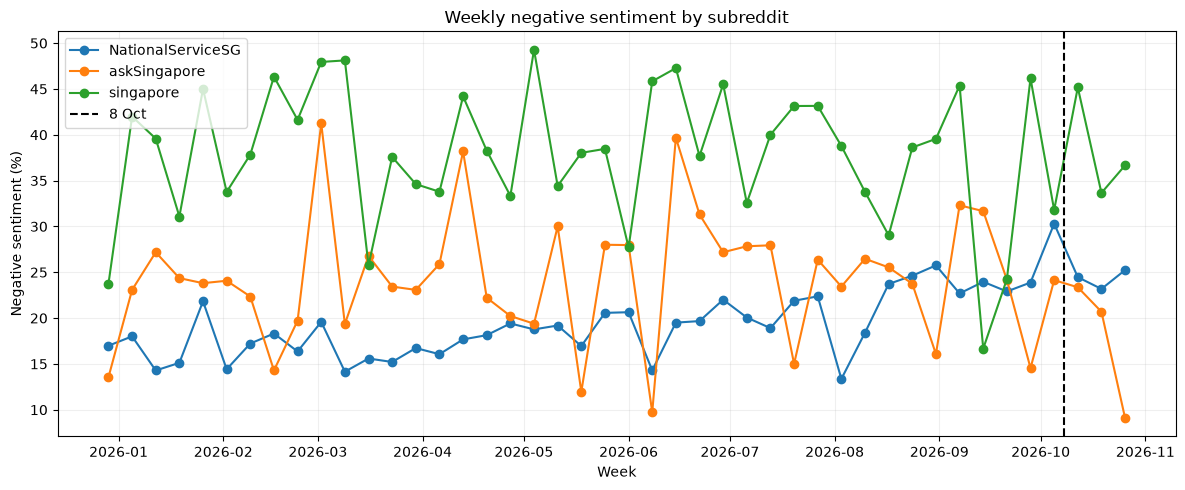

In [13]:
weekly = (
    doc.assign(
        week=doc["date"].dt.to_period("W-SUN").dt.start_time,
        is_negative=doc["sent_label"].eq("neg").astype(float)
    )
    .groupby(["week", "subreddit"])
    .agg(
        n=("doc_id", "size"),
        pct_negative=("is_negative", "mean"),
        mean_buyin=("net_buyin", "mean"),
        mean_stance=("net_stance", "mean"),
    )
    .reset_index()
)

fig, ax = plt.subplots(figsize=(12, 5))

for sub, g in weekly.groupby("subreddit"):
    g = g.sort_values("week")
    ax.plot(
        g["week"],
        g["pct_negative"] * 100,
        marker="o",
        label=sub
    )

ax.axvline(EVENT_DATE, color="black", linestyle="--", label="8 Oct")
ax.set(
    xlabel="Week",
    ylabel="Negative sentiment (%)",
    title="Weekly negative sentiment by subreddit"
)
ax.legend()
ax.grid(alpha=0.2)
plt.tight_layout()
plt.show()

* in the first analysis, the full-data window increase in negative sentiments driven by r/NationalServiceSG is reflective of a general increasing trend of negative sentiments on that subreddit that has persisted since the start of the year.
* the event seems to have done little to change existing trends.

### Follow Up 2: Why did sentiments change?
* topic prevalence: did some topics become more prevalent after the event?
* within-topic sentiment: did sentiments about those topics become more negative?

In [55]:
WINDOW = 14 #can change
w = doc.loc[
    ((doc["date"] >= EVENT_DATE - pd.Timedelta(days=WINDOW)) & (doc["date"] < EVENT_DATE))
    | ((doc["date"] > EVENT_DATE) & (doc["date"] <= EVENT_DATE + pd.Timedelta(days=WINDOW)))].copy()

w["period"] = np.where(w["date"] < EVENT_DATE, "before", "after")
w["topic_macro"] = w["topic_macro"].fillna("Unassigned")
w["negative"] = w["sent_label"].eq("neg").astype(float)
w['positive'] = w['sent_label'].eq('pos').astype(float)

# Rebuild the full 14-day dataset to avoid reusing a filtered w
WINDOW = 14

w = doc.loc[
    ((doc["date"] >= EVENT_DATE - pd.Timedelta(days=WINDOW))
     & (doc["date"] < EVENT_DATE))
    |
    ((doc["date"] > EVENT_DATE)
     & (doc["date"] <= EVENT_DATE + pd.Timedelta(days=WINDOW)))
].copy()

w["period"] = np.where(w["date"] < EVENT_DATE, "before", "after")
w["topic_macro"] = w["topic_macro"].fillna("Unassigned")
w["negative"] = w["sent_label"].eq("neg").astype(int)
w["positive"] = w["sent_label"].eq("pos").astype(int)

topic_tests = []

for topic in sorted(w["topic_macro"].unique()):
    d = w.copy()

    # Topic prevalence: binary indicator across ALL documents
    d["in_topic"] = d["topic_macro"].eq(topic).astype(int)

    prevalence = compare_test(d, "in_topic")

    # Within-topic negativity: only documents belonging to this topic
    subset = d[d["in_topic"] == 1]
    negativity = compare_test(subset, "negative")

    topic_tests.append({
        "topic_macro": topic,
        "share_diff_pp": prevalence["diff"] * 100,
        "share_ci_low": prevalence["ci_low"] * 100,
        "share_ci_high": prevalence["ci_high"] * 100,
        "share_p": prevalence["p"],
        "neg_diff_pp": negativity["diff"] * 100,
        "neg_ci_low": negativity["ci_low"] * 100,
        "neg_ci_high": negativity["ci_high"] * 100,
        "neg_p": negativity["p"],
        "n_before": (subset["period"] == "before").sum(),
        "n_after": (subset["period"] == "after").sum(),
    })

topic_tests = pd.DataFrame(topic_tests)

# Two distinct FDR families
topic_tests["share_q"] = add_fdr(topic_tests, "share_p")["q"]
topic_tests["neg_q"] = add_fdr(topic_tests, "neg_p")["q"]

display(topic_tests.sort_values("share_q").round(3))



display(w.groupby("period").agg(n=("doc_id", "size"),negative_pct=("negative", "mean")))

,topic_macro,share_diff_pp,share_ci_low,share_ci_high,share_p,neg_diff_pp,neg_ci_low,neg_ci_high,neg_p,n_before,n_after,share_q,neg_q
0,Admin & Logistics,2.302,0.220,4.384,0.030,10.795,-1.640,23.229,0.089,53,104,0.181,0.320
1,BMT & Training,-5.632,-10.657,-0.608,0.028,7.618,-0.970,16.206,0.082,323,157,0.181,0.320
8,Mental Health,3.014,0.367,5.662,0.026,11.170,-7.732,30.071,0.247,45,114,0.181,0.740
6,Gender & Diversity,2.426,-1.006,5.857,0.166,1.948,-24.841,28.737,0.887,20,77,0.549,0.939
12,Pay & Benefits,-2.526,-6.436,1.385,0.206,-8.009,-30.271,14.254,0.481,140,66,0.549,0.893
10,NS Policy & Society,3.101,-1.517,7.720,0.188,-1.013,-12.585,10.559,0.864,156,217,0.549,0.939
9,NS Life & Culture,-4.922,-12.678,2.835,0.214,7.054,-0.888,14.995,0.082,622,446,0.549,0.320
13,Physical Fitness & IPPT,1.943,-1.876,5.761,0.319,14.464,5.678,23.249,0.001,100,138,0.717,0.023
2,Career & Sign-on,0.836,-0.963,2.636,0.362,-2.736,-18.752,13.281,0.738,47,63,0.725,0.893
15,Reservist & ICT,0.851,-1.431,3.134,0.465,3.393,-13.957,20.744,0.701,62,77,0.836,0.893


,n,negative_pct
period,,
after,2425,0.272990
before,2668,0.226762


**Qualitative Manual Review**
* Adjusted the above code to WINDOW=30 before running below

In [ ]:
TOPICS = [  "Gender & Diversity","Physical Fitness & IPPT","Mental Health","NS Policy & Society"]

w_review = w.loc[w["topic_macro"].isin(TOPICS)].copy()
negative = w_review.loc[w_review["sent_label"].eq("pos")]
samples = pd.concat([g.sample(min(10, len(g)), random_state=42) for _, g in negative.groupby(["topic_macro", "period"])], ignore_index=True)

print(samples.groupby(["topic_macro", "period"]).size())

chunks = pd.concat([pd.read_parquet(DATA / "comments_chunks.parquet",columns=["doc_id", "chunk_id", "text"]),
    pd.read_parquet(DATA / "submissions_chunks.parquet",columns=["doc_id", "chunk_id", "text"])], ignore_index=True)

# Retain only chunks marked eligible
eligibility = pd.read_parquet(DATA / "chunk_eligibility.parquet")
chunks = chunks.merge(eligibility[["chunk_id", "eligible_content"]],on="chunk_id",validate="one_to_one")
chunks = chunks.loc[chunks["eligible_content"]]

# Reconstruct text from chunks
# Note: this is not guaranteed to reproduce the original
# post/comment verbatim if chunking modified or repeated text.
doc_text = (chunks.groupby("doc_id")["text"].agg(lambda s: "\n\n".join(s.dropna().astype(str))).rename("text").reset_index())
samples = samples.merge(doc_text,on="doc_id",how="left",validate="one_to_one")
samples["interpretation"] = ""
samples["notes"] = ""

cols = ["doc_id","subreddit","date","period","topic_macro","sent_neg","sent_pos","text","interpretation","notes",]
samples[cols].to_csv( DATA / "topic_discussion_review.csv",index=False)

topic_macro              period
Gender & Diversity       after      3
                         before     5
Mental Health            after     10
                         before    10
NS Policy & Society      after     10
                         before    10
Physical Fitness & IPPT  after     10
                         before    10
dtype: int64


Comparing negative sentiment samples in the 30 days before and after the event, for the 4 topics that experienced the greatest percentage increase in popularity

Gender & Diversity became more negative
* Before: discussing dating and nationality-related fairness
* After: almost entirely arguing about whether women should be conscripted

Mental health became more positive
* Before & After: either giving or soliciting advice on mental health issues. 
* AfteR: pleas to ask for help if needed get stronger

NS Policy & Society became more positive
* Before & After: discussing the necessity of conscription and whether women should be conscripted

Physical Fitness & IPPT became more negative
* Before: fitness advice
* After: haze **unrelated to the 8th october incident but happened within the 30 day window. ignore.


**Is increase in negativity attributed to topic prevalence or topic sentiment?**
* Is contribution of a topic to overall negativity because it is a pre-existing negative topic that became more popular, or
* is it because sentiments about the topic itself became more negative?

In [29]:
def decompose_topics(data, sentiment = 'negative'):
    counts = (data.groupby(["topic_macro", "period"]).agg(n=("doc_id", "size"),p_neg=(sentiment, "mean")).unstack("period"))

    n = counts["n"].reindex(columns=["before", "after"]).fillna(0)
    p = counts["p_neg"].reindex(columns=["before", "after"])

    # For topics absent in one period, use pooled rate
    pooled = ((p.fillna(0) * n).sum(axis=1)/ n.sum(axis=1))
    p = p.T.fillna(pooled).T

    wb = n["before"] / n["before"].sum()
    wa = n["after"] / n["after"].sum()

    pb = p["before"]
    pa = p["after"]

    out = pd.DataFrame({
        "n_before": n["before"],
        "n_after": n["after"],
        "share_before": wb,
        "share_after": wa,
        "neg_before": pb,
        "neg_after": pa,
    })

    out["composition_pp"] = ((wa - wb) * (pa + pb) / 2 * 100)

    out["within_pp"] = ((pa - pb) * (wa + wb) / 2 * 100)

    out["total_pp"] = (out["composition_pp"] + out["within_pp"])

    actual_change = 100 * (data.loc[data["period"].eq("after"), sentiment].mean()- data.loc[data["period"].eq("before"), sentiment].mean())

    assert np.isclose(out["total_pp"].sum(),actual_change)

    return out.sort_values("total_pp", ascending=False)

In [38]:
decomp = decompose_topics(w)
decomp_pos = decompose_topics(w, 'positive')
decomp_full = pd.merge(decomp,decomp_pos,on='topic_macro', how='inner',suffixes=('_neg', '_pos'))
display(decomp_full[["n_before_neg","n_after_neg","composition_pp_neg","within_pp_neg","total_pp_neg","n_before_pos","n_after_pos","composition_pp_pos","within_pp_pos","total_pp_pos"]].round(3)        )

print("\nOVERALL DECOMPOSITION")
for x,y in [('negative', decomp),('positive', decomp_pos)]:
    print(f"Composition ({x}):", round(y["composition_pp"].sum(), 3), "pp")
    print(f"Within-topic ({x}):", round(y["within_pp"].sum(), 3), "pp")
    print(f"Total ({x}):", round(y["total_pp"].sum(), 3), "pp")

,n_before_neg,n_after_neg,composition_pp_neg,within_pp_neg,total_pp_neg,n_before_pos,n_after_pos,composition_pp_pos,within_pp_pos,total_pp_pos
topic_macro,,,,,,,,,,
Gender & Diversity,20,77,1.236,0.038,1.275,20,77,0.153,-0.145,0.008
NS Policy & Society,156,217,1.316,-0.075,1.241,156,217,0.203,-0.357,-0.154
Mental Health,45,114,0.704,0.357,1.061,45,114,0.612,0.161,0.772
Physical Fitness & IPPT,100,138,0.296,0.683,0.979,100,138,0.297,-0.350,-0.052
Admin & Logistics,53,104,0.385,0.339,0.724,53,104,0.263,-0.113,0.150
Discipline & Misconduct,168,163,0.141,0.380,0.521,168,163,0.032,0.054,0.086
Medical & Health,298,277,0.046,0.345,0.390,298,277,0.029,-0.100,-0.071
Unassigned,125,101,-0.116,0.483,0.368,125,101,-0.098,-0.096,-0.195
Reservist & ICT,62,77,0.207,0.093,0.300,62,77,0.131,0.225,0.356



OVERALL DECOMPOSITION
Composition (negative): 0.599 pp
Within-topic (negative): 4.024 pp
Total (negative): 4.623 pp
Composition (positive): -0.991 pp
Within-topic (positive): -0.093 pp
Total (positive): -1.084 pp


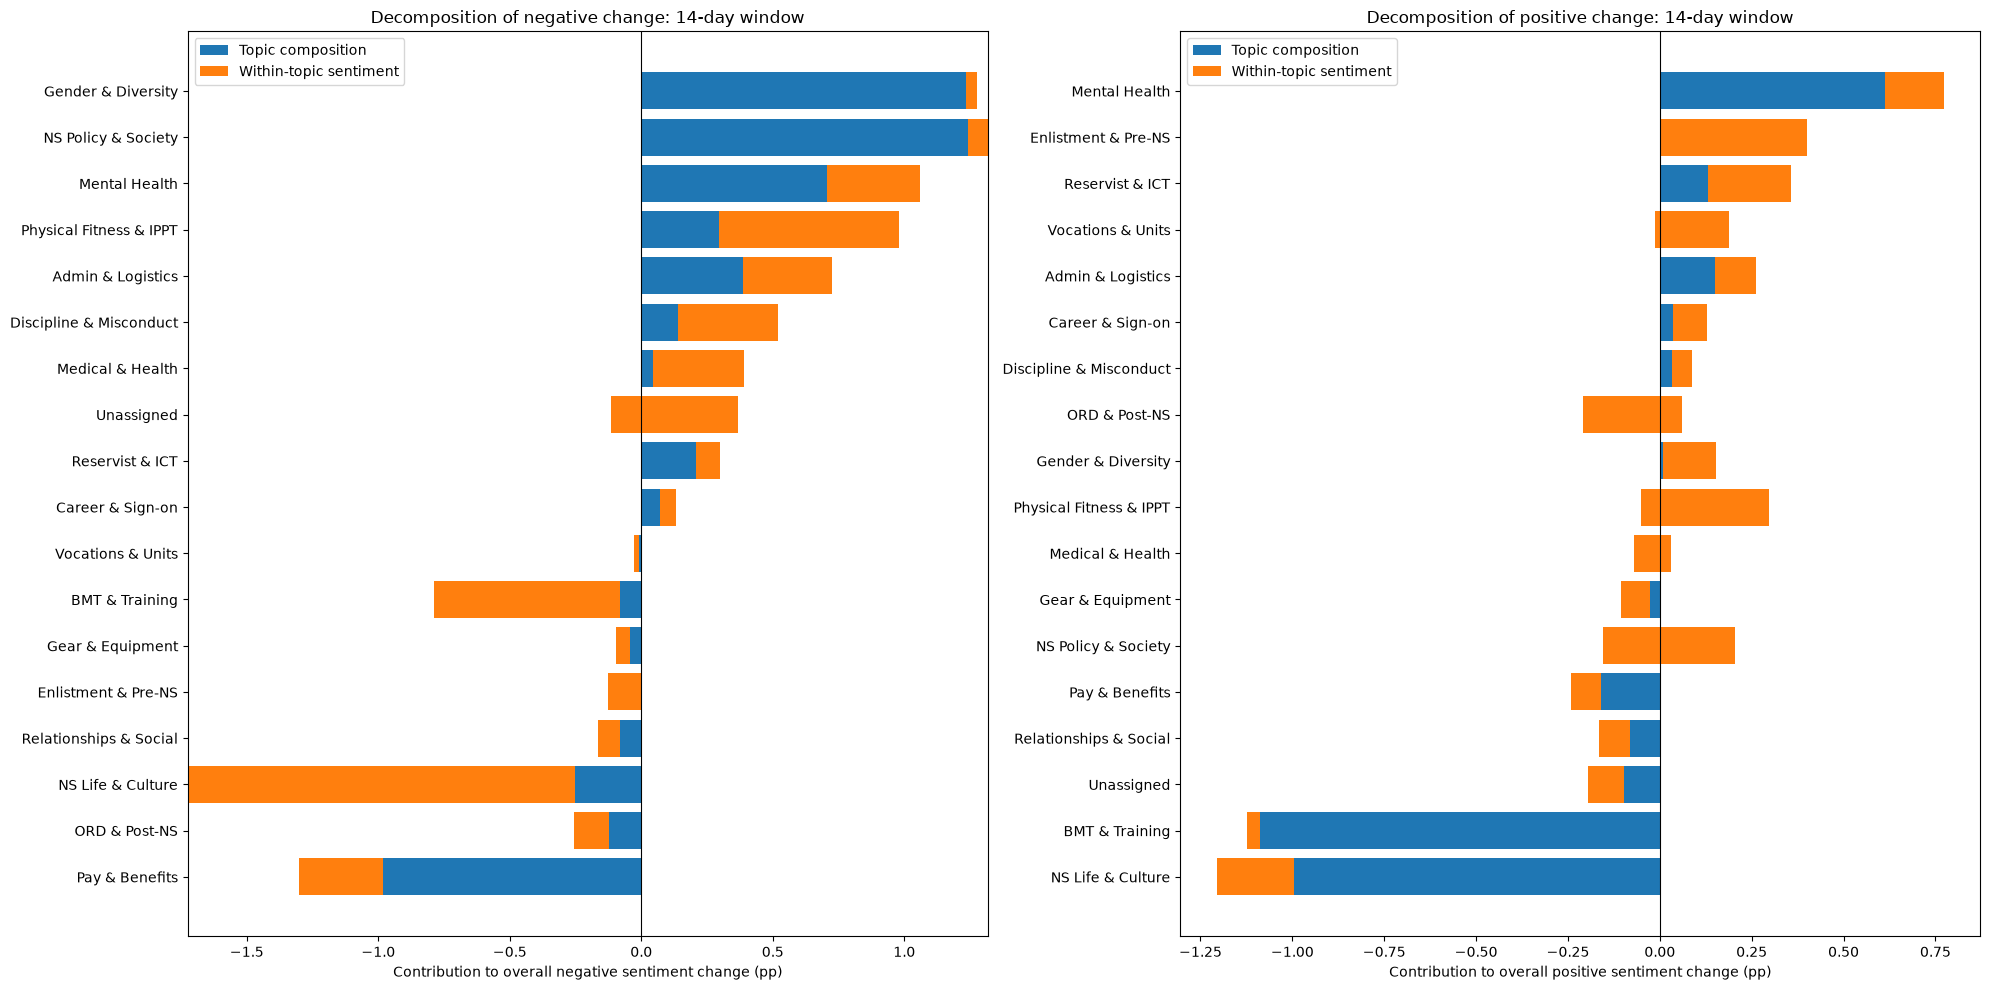

In [40]:
fig, ax = plt.subplots(nrows=1, ncols=2,figsize=(20, 10))
for i,j in [(0,'negative'),(1,'positive')]:
    plot_df = decomp_full.sort_values(f"total_pp_{j[:3]}")
    ax[i].barh(plot_df.index,plot_df[f"composition_pp_{j[:3]}"],label="Topic composition")
    ax[i].barh(plot_df.index,plot_df[f"within_pp_{j[:3]}"],left=plot_df[f"composition_pp_{j[:3]}"],label="Within-topic sentiment")
    ax[i].axvline(0, color="black", linewidth=0.8)
    ax[i].set(xlabel=f"Contribution to overall {j} sentiment change (pp)",title=f"Decomposition of {j} change: {WINDOW}-day window")
    ax[i].legend()
plt.tight_layout()
plt.show()

In [56]:
def bootstrap_decomposition(data, B=500, seed=42):
    rng = np.random.default_rng(seed)
    results = []

    # Precompute thread-level counts
    thread_data = (data.groupby(["period", "post_id", "topic_macro"]).agg(n=("doc_id", "size"),n_negative=("negative", "sum")).reset_index())

    topics = sorted(thread_data["topic_macro"].unique())

    # Sample threads separately within each period
    groups = {}
    for period in ["before", "after"]:
        part = thread_data[thread_data["period"] == period]
        groups[period] = [g[["topic_macro", "n", "n_negative"]] for _, g in part.groupby("post_id")]

    for _ in range(B):
        summaries = {}

        for period in ["before", "after"]:
            pool = groups[period]
            sampled = rng.integers(0, len(pool), len(pool))

            s = pd.concat([pool[i] for i in sampled],ignore_index=True)

            summaries[period] = (
                s.groupby("topic_macro")[["n", "n_negative"]]
                .sum()
                .reindex(topics, fill_value=0)
            )

        nb = summaries["before"]["n"]
        na = summaries["after"]["n"]

        pb = summaries["before"]["n_negative"].div(nb.replace(0, np.nan))
        pa = summaries["after"]["n_negative"].div(na.replace(0, np.nan))

        pooled = (
            summaries["before"]["n_negative"]
            + summaries["after"]["n_negative"]
        ) / (nb + na).replace(0, np.nan)

        pb = pb.fillna(pooled).fillna(0)
        pa = pa.fillna(pooled).fillna(0)

        wb = nb / nb.sum()
        wa = na / na.sum()

        composition = ((wa - wb) * (pa + pb) / 2).sum() * 100
        within = ((pa - pb) * (wa + wb) / 2).sum() * 100

        results.append({
            "composition_pp": composition,
            "within_pp": within,
            "total_pp": composition + within
        })

    return pd.DataFrame(results)

In [57]:
decomp = decompose_topics(w)

boot = bootstrap_decomposition(w, B=500)

point = {
    "composition_pp": decomp["composition_pp"].sum(),
    "within_pp": decomp["within_pp"].sum(),
    "total_pp": decomp["total_pp"].sum(),
}

decomp_ci = pd.DataFrame({
    "estimate": pd.Series(point),
    "ci_low": boot.quantile(0.025),
    "ci_high": boot.quantile(0.975),
})

display(decomp_ci.round(3))

,estimate,ci_low,ci_high
composition_pp,0.599,-1.773,3.018
within_pp,4.024,0.391,7.957
total_pp,4.623,-0.228,9.457


In [41]:
results = []

for sub in ["All", *sorted(w["subreddit"].unique())]:
    subset = w if sub == "All" else w[w["subreddit"] == sub]

    d = pd.merge(decompose_topics(subset),decompose_topics(subset,'positive'),on='topic_macro', how='inner',suffixes=('_neg', '_pos'))

    results.append({"subreddit": sub,
        "sample_size_neg": d.n_before_neg.sum() + d.n_after_neg.sum(),"composition_pp_neg": d["composition_pp_neg"].sum(),"within_pp_neg": d["within_pp_neg"].sum(),"total_pp_neg": d["total_pp_neg"].sum(),
        "sample_size_pos": d.n_before_pos.sum() + d.n_after_pos.sum(),"composition_pp_pos": d["composition_pp_pos"].sum(),"within_pp_pos": d["within_pp_pos"].sum(),"total_pp_pos": d["total_pp_pos"].sum(),
    })

subreddit_decomp = pd.DataFrame(results)

display(subreddit_decomp.round(3))

,subreddit,sample_size_neg,composition_pp_neg,within_pp_neg,total_pp_neg,sample_size_pos,composition_pp_pos,within_pp_pos,total_pp_pos
0,All,5093.0,0.599,4.024,4.623,5093.0,-0.991,-0.093,-1.084
1,NationalServiceSG,4521.0,0.878,3.013,3.891,4521.0,-0.904,0.063,-0.841
2,askSingapore,284.0,-1.031,5.782,4.751,284.0,-7.416,10.499,3.083
3,singapore,288.0,0.686,10.773,11.458,288.0,0.242,-5.971,-5.729


### FOLLOW UP 3: WHY DID COMMITMENT and STANCE CHANGE?
* In part 1, the only significant changes occured in the 21-day window for commitment and stance.

In [58]:
c = doc.copy()

# Document-level dominant cascade categories
buyin_cols = ["prob_buyin_committed","prob_buyin_uncommitted","prob_buyin_neutral",]
stance_cols = ["prob_stance_supportive","prob_stance_critical","prob_stance_neutral",]

print("Missing columns:",set(buyin_cols + stance_cols) - set(c.columns))

c["buyin_label"] = (c[buyin_cols].idxmax(axis=1).str.replace("prob_buyin_", "", regex=False))
c["stance_label"] = (c[stance_cols].idxmax(axis=1).str.replace("prob_stance_", "", regex=False))

# Preserve missing cascade predictions
c.loc[c[buyin_cols].isna().all(axis=1), "buyin_label"] = np.nan
c.loc[c[stance_cols].isna().all(axis=1), "stance_label"] = np.nan

print(c["buyin_label"].value_counts(dropna=False))
print(c["stance_label"].value_counts(dropna=False))

Missing columns: set()
buyin_label
neutral        49884
uncommitted     2751
committed       2430
Name: count, dtype: int64
stance_label
neutral       50894
critical       2759
supportive     1412
Name: count, dtype: int64


In [59]:
# 1 = expresses buy-in / policy stance
# 0 = neutral
c["buyin_expressed"] = np.where(c["buyin_label"].notna(),c["buyin_label"].ne("neutral").astype(float),np.nan)
c["stance_expressed"] = np.where(c["stance_label"].notna(),c["stance_label"].ne("neutral").astype(float),np.nan)

# Direction only among documents expressing a position
c["uncommitted_given_buyin"] = np.where(c["buyin_label"].isin(["committed", "uncommitted"]),c["buyin_label"].eq("uncommitted").astype(float),np.nan)
c["critical_given_stance"] = np.where(c["stance_label"].isin(["supportive", "critical"]),c["stance_label"].eq("critical").astype(float),np.nan)

In [60]:
OUTCOMES = {
    "buyin_expressed": "Buy-in expressed",
    "uncommitted_given_buyin": "Uncommitted | buy-in expressed",
    "stance_expressed": "Stance expressed",
    "critical_given_stance": "Critical | stance expressed",
}

def commitment_comparison(data, days=14):
    d = data.loc[((data["date"] >= EVENT_DATE - pd.Timedelta(days=days)) & (data["date"] < EVENT_DATE))
        | ((data["date"] > EVENT_DATE) & (data["date"] <= EVENT_DATE + pd.Timedelta(days=days)))
    ].copy()

    d["period"] = np.where(d["date"] < EVENT_DATE, "before", "after")

    rows = []

    for sub in ["All", *sorted(d["subreddit"].dropna().unique())]:
        part = d if sub == "All" else d[d["subreddit"] == sub]

        for outcome, label in OUTCOMES.items():
            a = part.loc[part["period"].eq("before"), outcome].dropna()
            b = part.loc[part["period"].eq("after"), outcome].dropna()

            test = compare_test(part, outcome)

            rows.append({
                "window": days,
                "subreddit": sub,
                "measure": label,
                "n_before": len(a),
                "n_after": len(b),
                "before_pct": a.mean() * 100,
                "after_pct": b.mean() * 100,
                "change_pp": test["diff"] * 100,
                "ci_low": test["ci_low"] * 100,
                "ci_high": test["ci_high"] * 100,
                "p": test["p"],
            })

    return pd.DataFrame(rows)


commitment_results = commitment_comparison(c, days=14)

# FDR across the four outcomes and three subreddits:
# 12 comparisons in one family.
commitment_results["q"] = np.nan

mask = (commitment_results["subreddit"].ne("All") & commitment_results["p"].notna())

commitment_results.loc[mask, "q"] = multipletests(commitment_results.loc[mask, "p"], method="fdr_bh")[1]

display(commitment_results.round(3))

,window,subreddit,measure,n_before,n_after,before_pct,after_pct,change_pp,ci_low,ci_high,p,q
0,14,All,Buy-in expressed,2668,2425,9.483,12.082,2.600,-0.410,5.609,0.090,NaN
1,14,All,Uncommitted | buy-in expressed,253,293,57.708,50.853,-6.854,-16.120,2.412,0.147,NaN
2,14,All,Stance expressed,2668,2425,8.921,9.608,0.688,-2.369,3.745,0.659,NaN
3,14,All,Critical | stance expressed,238,233,73.950,69.099,-4.851,-13.903,4.201,0.294,NaN
4,14,NationalServiceSG,Buy-in expressed,2474,2047,9.660,11.138,1.478,-1.666,4.622,0.357,0.642
5,14,NationalServiceSG,Uncommitted | buy-in expressed,239,228,58.159,54.386,-3.773,-13.511,5.965,0.448,0.671
6,14,NationalServiceSG,Stance expressed,2474,2047,8.812,8.256,-0.556,-3.687,2.576,0.728,0.819
7,14,NationalServiceSG,Critical | stance expressed,218,169,74.312,73.373,-0.939,-10.183,8.304,0.842,0.842
8,14,askSingapore,Buy-in expressed,98,186,8.163,16.667,8.503,-2.966,19.973,0.146,0.439
9,14,askSingapore,Uncommitted | buy-in expressed,8,31,37.500,45.161,NaN,NaN,NaN,NaN,NaN


In [ ]:
commitment_windows = pd.concat([commitment_comparison(c, days=7),commitment_comparison(c, days=14),], ignore_index=True)

display(commitment_windows.pivot_table(index=["subreddit", "measure"],columns="window",values="change_pp").round(2))

window                                               7      14
subreddit         measure                                     
All               Buy-in expressed                 1.21   2.60
                  Critical | stance expressed     -3.58  -4.85
                  Stance expressed                -1.83   0.69
                  Uncommitted | buy-in expressed  -6.17  -6.85
NationalServiceSG Buy-in expressed                 0.29   1.48
                  Critical | stance expressed     -2.45  -0.94
                  Stance expressed                -3.02  -0.56
                  Uncommitted | buy-in expressed  -3.30  -3.77
askSingapore      Buy-in expressed                 8.77   8.50
                  Stance expressed                 4.42   6.13
singapore         Buy-in expressed                11.11  11.46
                  Critical | stance expressed      5.52  -9.17
                  Stance expressed                 3.45   6.77

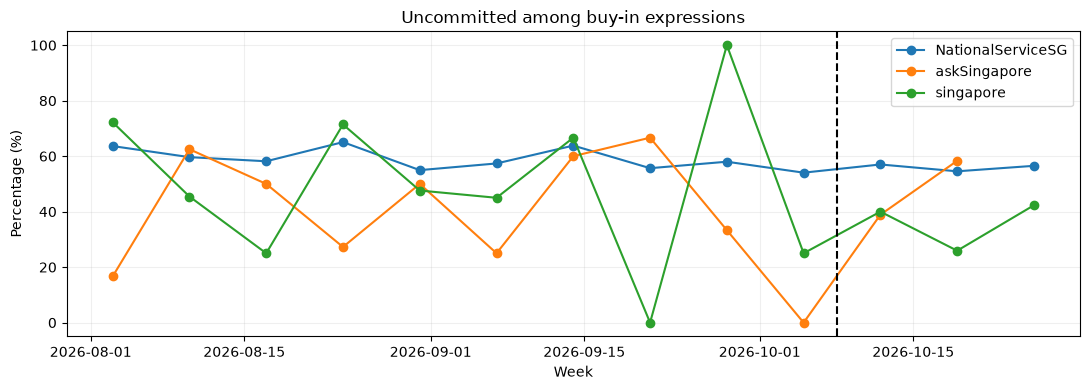

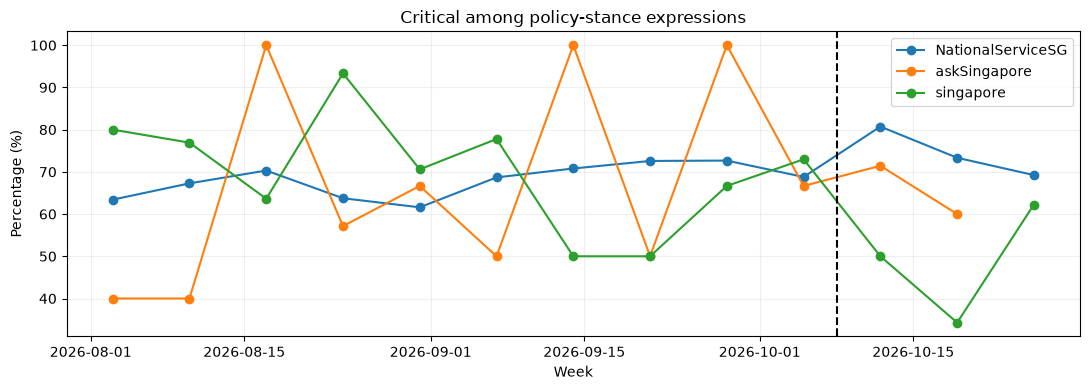

In [62]:
weekly_c = (
    c.assign(
        week=c["date"].dt.to_period("W-SUN").dt.start_time
    )
    .groupby(["week", "subreddit"])
    .agg(
        n=("doc_id", "size"),
        pct_uncommitted=("uncommitted_given_buyin", "mean"),
        pct_critical=("critical_given_stance", "mean"),
    )
    .reset_index()
)

recent = weekly_c.loc[
    weekly_c["week"] >= pd.Timestamp("2026-08-01")
]

for measure, title in [
    ("pct_uncommitted", "Uncommitted among buy-in expressions"),
    ("pct_critical", "Critical among policy-stance expressions"),
]:
    fig, ax = plt.subplots(figsize=(11, 4))

    for sub, g in recent.groupby("subreddit"):
        ax.plot(
            g["week"],
            g[measure] * 100,
            marker="o",
            label=sub
        )

    ax.axvline(EVENT_DATE, color="black", linestyle="--")
    ax.set(
        title=title,
        xlabel="Week",
        ylabel="Percentage (%)",
    )
    ax.legend()
    ax.grid(alpha=0.2)
    plt.tight_layout()
    plt.show()

### FOLLOW UP 4: Interrupted time-series analysis

There is some evidence that negative sentiment increased around the transition point. However, previous analyses compared 2 window averages, which resulted in insignificant findings, likely because sentiments fluctuate a lot and may cancel each other out. Using ITS, we test for
* Immediate Change: sudden decrease around event date?
* Change in trend: increase/decrease faster than before?
* Overall pattern: is post-event trajectory different from what pre-event trajectory would have predicted?

In [78]:
def run_its(data, outcome, pre_days=60, post_days=21):
    d = data.loc[data["date"].between(EVENT_DATE - pd.Timedelta(days=pre_days),EVENT_DATE + pd.Timedelta(days=post_days))].dropna(subset=[outcome]).copy()

    daily = (
        d.groupby("date")
        .agg(y=(outcome, "mean"),n=(outcome, "size"))
        .reset_index()
        .sort_values("date")
    )

    # Ensure the requested date window is fully covered
    expected = pd.date_range(EVENT_DATE - pd.Timedelta(days=pre_days),EVENT_DATE + pd.Timedelta(days=post_days))
    missing = expected.difference(daily["date"])

    if len(missing):
        raise ValueError(f"Missing dates: {missing.tolist()}")

    daily["t"] = (daily["date"] - EVENT_DATE).dt.days
    daily["event_day"] = daily["t"].eq(0).astype(int)
    daily["post"] = daily["t"].gt(0).astype(int)
    daily["days_after"] = np.where(daily["post"].eq(1),daily["t"] - 1,0)

    predictors = ["t", "event_day", "post", "days_after"]
    X = sm.add_constant(daily[predictors])

    fit = sm.WLS(daily["y"],X,weights=daily["n"]).fit(cov_type="HAC",cov_kwds={"maxlags": 7})

    daily["fitted"] = fit.predict(X)

    # Projection of the pre-event trend
    X_cf = X.copy()
    X_cf[["event_day", "post", "days_after"]] = 0
    daily["baseline"] = fit.predict(X_cf)

    return fit, daily


def its_summary(fit, outcome):
    ci = fit.conf_int()

    terms = ["t", "event_day", "post", "days_after"]

    return pd.DataFrame({
        "outcome": outcome,
        "term": terms,
        "estimate_pp": fit.params[terms].values * 100,
        "ci_low_pp": ci.loc[terms, 0].values * 100,
        "ci_high_pp": ci.loc[terms, 1].values * 100,
        "p": fit.pvalues[terms].values,
    })

def plot_its(outcome):
    daily = daily_results[outcome]
    label = OUTCOMES[outcome]

    fig, ax = plt.subplots(figsize=(11, 4.5))

    ax.scatter(daily["date"],daily["y"] * 100,color="gray",alpha=0.5,s=25,label="Observed daily proportion")

    pre = daily["date"] < EVENT_DATE
    post = daily["date"] > EVENT_DATE

    ax.plot(daily.loc[pre, "date"],daily.loc[pre, "fitted"] * 100, color="steelblue",lw=2.5,label="Fitted ITS trend")

    ax.plot(daily.loc[post, "date"],daily.loc[post, "fitted"] * 100,color="steelblue", lw=2.5)
    ax.plot(daily.loc[post, "date"],daily.loc[post, "baseline"] * 100,color="darkorange",linestyle="--",lw=2,label="Projected pre-event trend"
    )

    event_row = daily["date"] == EVENT_DATE
    ax.scatter(daily.loc[event_row, "date"],daily.loc[event_row, "y"] * 100,color="crimson",s=65,zorder=5,label="8 Oct observation")

    ax.axvline(EVENT_DATE,color="black",linestyle=":",label="8 Oct transition")

    ax.set(title=f"Interrupted time series: {label}",xlabel="Date",ylabel="Percentage of documents (%)")

    ax.legend()
    ax.grid(alpha=0.15)
    plt.tight_layout()
    plt.show()


**SENTIMENTS**

In [79]:
its_doc = c.copy()
its_doc["date"] = pd.to_datetime(its_doc["date"]).dt.normalize()

# Sentiment proportions
for label in ["neg", "neu", "pos"]:
    its_doc[f"pct_{label}"] = np.where(
        its_doc["sent_label"].notna(),
        its_doc["sent_label"].eq(label).astype(float),
        np.nan
    )

OUTCOMES = {
    "pct_neg": "Negative sentiment",
    "pct_neu": "Neutral sentiment",
    "pct_pos": "Positive sentiment",
    "buyin_expressed": "Buy-in expressed",
    "uncommitted_given_buyin": "Uncommitted | buy-in expressed",
    "stance_expressed": "Policy stance expressed",
    "critical_given_stance": "Critical | stance expressed",
}

assert set(OUTCOMES).issubset(its_doc.columns)

fits = {}
daily_results = {}
tables = []

for outcome, label in OUTCOMES.items():
    fit, daily = run_its(
        its_doc,
        outcome,
        pre_days=60,
        post_days=21
    )

    fits[outcome] = fit
    daily_results[outcome] = daily
    tables.append(its_summary(fit, label))

its_results = pd.concat(tables, ignore_index=True)

# Adjust across outcomes within each event-related term
its_results["q"] = np.nan

for term in ["event_day", "post", "days_after"]:
    mask = (
        its_results["term"].eq(term)
        & its_results["p"].notna()
    )

    its_results.loc[mask, "q"] = multipletests(
        its_results.loc[mask, "p"],
        method="fdr_bh"
    )[1]

display(its_results.round(3))

for outcome, daily in daily_results.items():
    invalid = (~daily["fitted"].between(0, 1)).sum()
    print(outcome, "out-of-range fitted days:", invalid)


,outcome,term,estimate_pp,ci_low_pp,ci_high_pp,p,q
0,Negative sentiment,t,0.015,-0.081,0.111,0.765,NaN
1,Negative sentiment,event_day,10.307,7.370,13.245,0.000,0.000
2,Negative sentiment,post,5.405,0.635,10.176,0.026,0.062
3,Negative sentiment,days_after,-0.378,-0.703,-0.053,0.023,0.048
4,Neutral sentiment,t,-0.040,-0.138,0.058,0.425,NaN
5,Neutral sentiment,event_day,-4.345,-7.791,-0.898,0.013,0.013
6,Neutral sentiment,post,-5.247,-9.596,-0.899,0.018,0.062
7,Neutral sentiment,days_after,0.575,0.327,0.824,0.000,0.000
8,Positive sentiment,t,0.025,-0.021,0.072,0.289,NaN
9,Positive sentiment,event_day,-5.963,-7.612,-4.313,0.000,0.000


pct_neg out-of-range fitted days: 0
pct_neu out-of-range fitted days: 0
pct_pos out-of-range fitted days: 0
buyin_expressed out-of-range fitted days: 0
uncommitted_given_buyin out-of-range fitted days: 0
stance_expressed out-of-range fitted days: 0
critical_given_stance out-of-range fitted days: 0


* t = pre-event change in negativity, pp/day
* post = immediate change on 9 october,pp
* days_after = additional change in trend after 8 october, pp/day

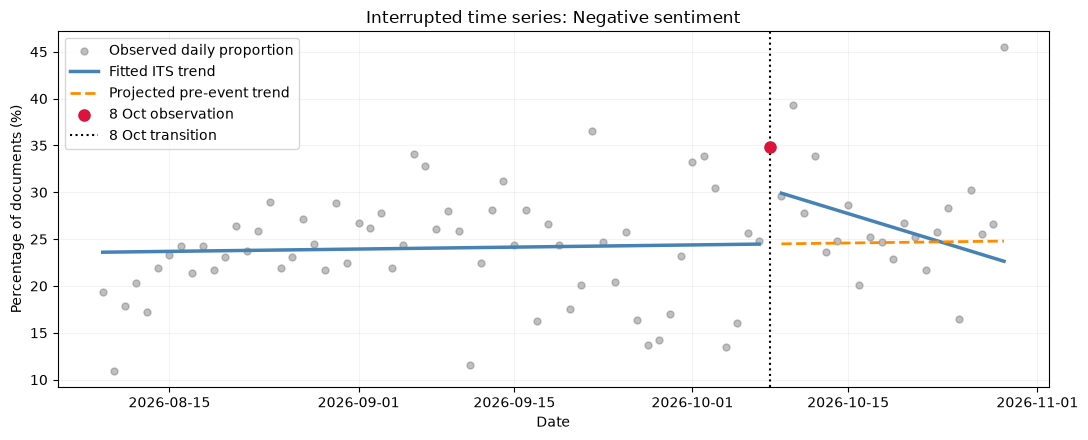

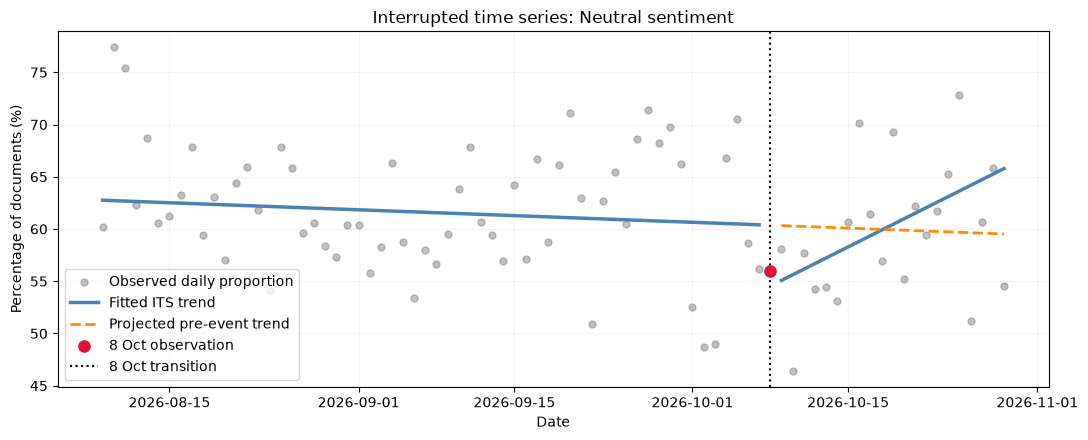

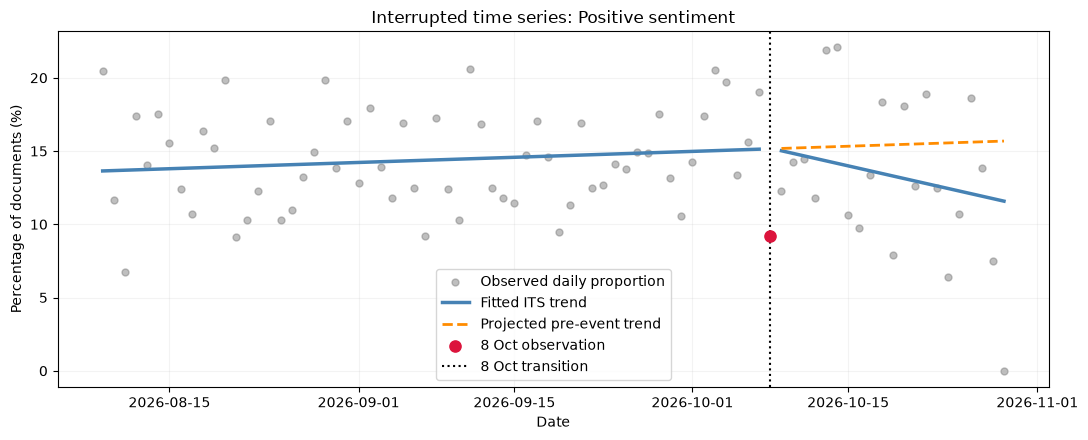

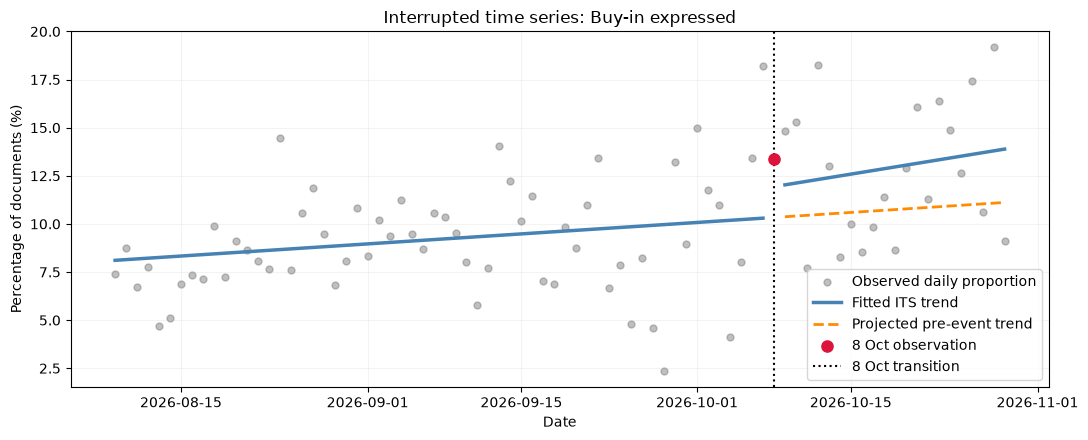

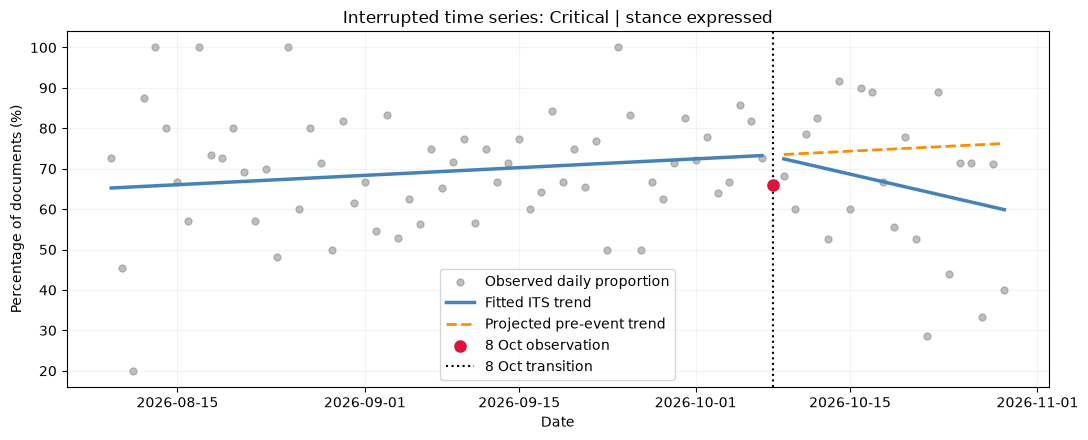

In [80]:

plot_its("pct_neg")
plot_its("pct_neu")
plot_its("pct_pos")

plot_its("buyin_expressed")
plot_its("critical_given_stance")